In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install ta

  Preparing metadata (setup.py) ... done
  Created wheel for ta: filename=ta-0.11.0-py3-none-any.whl size=29482 sha256=cadde182dac3b903addcdefa178b6ef5bfb3b60781a95754a53989f23263455e
  Stored in directory: /root/.cache/pip/wheels/e3/3a/ee/4955a26c90a4b7deb6d725dc8ec7b8604a7aef44e43a2e8af7
Successfully built ta


In [3]:
!pip install pytorch_lightning

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 27.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 57.0 MB/s eta 0:00:00


In [4]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import math
import ta
import pytorch_lightning as pl
import torch
import torch.nn as nn
import torchmetrics
from pytorch_lightning.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    LearningRateMonitor,
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

device = 'cuda' if torch.cuda.is_available() else 'cpu'


In [5]:
#df = pd.read_csv("gold_stock.csv")

file_path = "/content/drive/MyDrive/GoldPricePrediction/gold_stock.csv"
df = pd.read_csv(file_path)

In [6]:
df.head()

,Price,Close,High,Low,Open,Volume
0,Ticker,GOLD,GOLD,GOLD,GOLD,GOLD
1,Date,NaN,NaN,NaN,NaN,NaN
2,2014-03-17,4.711997032165527,4.85016815549002,4.425025639793251,4.425025639793251,68200
3,2014-03-18,5.048568248748779,5.278853682840762,4.694282757608514,4.711997099740122,135600
4,2014-03-19,4.959996223449707,5.1017102661133835,4.90685354191906,5.013138904980353,25600


In [7]:
df.tail()

,Price,Close,High,Low,Open,Volume
2965,2025-12-24,34.49665069580078,34.86352978677981,33.118371818243254,33.56457438016267,632900
2966,2025-12-26,34.298336029052734,35.40889108972075,33.475332803245784,35.20066272507017,519400
2967,2025-12-29,33.13819885253906,33.765864568292805,32.483764161201734,33.46541808947349,543700
2968,2025-12-30,33.167945861816406,33.60423436098219,32.860558461759986,33.48524727621538,478900
2969,2025-12-31,33.76288604736328,34.07027345633446,33.26710210016989,33.85212730915934,401800


In [8]:
df.shape

(2970, 6)

In [9]:
df.index

RangeIndex(start=0, stop=2970, step=1)

In [10]:
df.columns

Index(['Price', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='object')

In [11]:
print(df.dtypes)

Price     object
Close     object
High      object
Low       object
Open      object
Volume    object
dtype: object


In [12]:
gold = pd.read_csv(file_path, header=None)
gold

,0,1,2,3,4,5
0,Price,Close,High,Low,Open,Volume
1,Ticker,GOLD,GOLD,GOLD,GOLD,GOLD
2,Date,NaN,NaN,NaN,NaN,NaN
3,2014-03-17,4.711997032165527,4.85016815549002,4.425025639793251,4.425025639793251,68200
4,2014-03-18,5.048568248748779,5.278853682840762,4.694282757608514,4.711997099740122,135600
...,...,...,...,...,...,...
2966,2025-12-24,34.49665069580078,34.86352978677981,33.118371818243254,33.56457438016267,632900
2967,2025-12-26,34.298336029052734,35.40889108972075,33.475332803245784,35.20066272507017,519400
2968,2025-12-29,33.13819885253906,33.765864568292805,32.483764161201734,33.46541808947349,543700
2969,2025-12-30,33.167945861816406,33.60423436098219,32.860558461759986,33.48524727621538,478900


In [13]:
gold = gold.iloc[3:].reset_index(drop=True)
gold.head()

,0,1,2,3,4,5
0,2014-03-17,4.711997032165527,4.85016815549002,4.425025639793251,4.425025639793251,68200
1,2014-03-18,5.048568248748779,5.278853682840762,4.694282757608514,4.711997099740122,135600
2,2014-03-19,4.959996223449707,5.1017102661133835,4.90685354191906,5.013138904980353,25600
3,2014-03-20,4.959996223449707,4.959996223449707,4.889493292947593,4.959996223449707,8200
4,2014-03-21,4.69074010848999,4.92456849288367,4.6057116665055595,4.92456849288367,10600


In [14]:
gold.shape

(2968, 6)

In [15]:
gold.columns = ['Date', 'Close', 'High', 'Low', 'Open', 'Volume']

gold.head()

,Date,Close,High,Low,Open,Volume
0,2014-03-17,4.711997032165527,4.85016815549002,4.425025639793251,4.425025639793251,68200
1,2014-03-18,5.048568248748779,5.278853682840762,4.694282757608514,4.711997099740122,135600
2,2014-03-19,4.959996223449707,5.1017102661133835,4.90685354191906,5.013138904980353,25600
3,2014-03-20,4.959996223449707,4.959996223449707,4.889493292947593,4.959996223449707,8200
4,2014-03-21,4.69074010848999,4.92456849288367,4.6057116665055595,4.92456849288367,10600


In [16]:
gold["Date"] = pd.to_datetime(gold["Date"])

for col in ['Close', 'High', 'Low', 'Open', 'Volume']:
    gold[col] = pd.to_numeric(gold[col], errors="coerce")

print(gold.head())
print(gold.info())
print(gold.dtypes)

        Date     Close      High       Low      Open  Volume
0 2014-03-17  4.711997  4.850168  4.425026  4.425026   68200
1 2014-03-18  5.048568  5.278854  4.694283  4.711997  135600
2 2014-03-19  4.959996  5.101710  4.906854  5.013139   25600
3 2014-03-20  4.959996  4.959996  4.889493  4.959996    8200
4 2014-03-21  4.690740  4.924568  4.605712  4.924568   10600
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2968 entries, 0 to 2967
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    2968 non-null   datetime64[ns]
 1   Close   2968 non-null   float64       
 2   High    2968 non-null   float64       
 3   Low     2968 non-null   float64       
 4   Open    2968 non-null   float64       
 5   Volume  2968 non-null   int64         
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 139.3 KB
None
Date      datetime64[ns]
Close            float64
High             float64
Low              float64


In [18]:
def add_features(df):

    df = df.copy()

    # =====================
    # Returns
    # =====================

    df["return_1d"] = np.log(
         df["Close"]/ df["Close"].shift(1)
    )

    df["return_5d"] = np.log(
        df["Close"] / df["Close"].shift(5)
    )

    df["return_20d"] = np.log(
        df["Close"] / df["Close"].shift(20)
    )

    # =====================
    # RSI
    # =====================

    df["rsi"] = ta.momentum.RSIIndicator(
        close=df["Close"],
        window=14
    ).rsi()

    # =====================
    # Moving Averages
    # =====================

    sma14 = df["Close"].rolling(14).mean()
    sma28 = df["Close"].rolling(28).mean()

    df["sma_ratio"] = sma14 / sma28

    # Distance from MA
    df["price_vs_sma14"] = (
        df["Close"] - sma14
    ) / sma14

    # =====================
    # Volatility
    # =====================

    df["volatility_10"] = (
        df["return_1d"]
        .rolling(10)
        .std()
    )

    df["volatility_20"] = (
        df["return_1d"]
        .rolling(20)
        .std()
    )

    # =====================
    # MACD
    # =====================

    macd = ta.trend.MACD(df["Close"])

    df["macd"] = macd.macd()

    df["macd_signal"] = macd.macd_signal()

    df["macd_diff"] = macd.macd_diff()

    # =====================
    # Bollinger Bands
    # =====================

    bb = ta.volatility.BollingerBands(
        close=df["Close"],
        window=20,
        window_dev=2
    )

    upper = bb.bollinger_hband()
    lower = bb.bollinger_lband()

    df["bollinger_position"] = (
        (df["Close"] - lower)
        / (upper - lower)
    )

    # =====================
    # Volume Features
    # =====================

    '''df["volume_change"] = np.log(
        df["Volume"] / df["Volume"].shift(1)
    ) '''

    prev_volume = df["Volume"].shift(1)

    df["volume_change"] = np.log(
        df["Volume"].where(df["Volume"] > 0) /
        prev_volume.where(prev_volume > 0)
    )

    # =====================
    # Cleanup
    # =====================

    return df.dropna().reset_index(drop=True)

In [19]:
gold = add_features(gold)
gold.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2911 entries, 0 to 2910
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Date                2911 non-null   datetime64[ns]
 1   Close               2911 non-null   float64       
 2   High                2911 non-null   float64       
 3   Low                 2911 non-null   float64       
 4   Open                2911 non-null   float64       
 5   Volume              2911 non-null   int64         
 6   return_1d           2911 non-null   float64       
 7   return_5d           2911 non-null   float64       
 8   return_20d          2911 non-null   float64       
 9   rsi                 2911 non-null   float64       
 10  sma_ratio           2911 non-null   float64       
 11  price_vs_sma14      2911 non-null   float64       
 12  volatility_10       2911 non-null   float64       
 13  volatility_20       2911 non-null   float64     

In [20]:
gold.head()

,Date,Close,High,Low,Open,Volume,return_1d,return_5d,return_20d,rsi,sma_ratio,price_vs_sma14,volatility_10,volatility_20,macd,macd_signal,macd_diff,bollinger_position,volume_change
0,2014-05-02,4.152226,4.233712,4.152226,4.233712,2200,0.005133,-0.003407,-0.094379,41.613567,0.962304,-0.001946,0.023370,0.019138,-0.110822,-0.125350,0.014528,0.360016,0.451985
1,2014-05-05,4.162855,4.233712,4.060112,4.177027,22400,0.002556,-0.004246,-0.063474,42.343174,0.965970,0.001766,0.021947,0.018362,-0.103581,-0.120996,0.017415,0.407460,2.320604
2,2014-05-06,4.074284,4.155769,4.074284,4.155769,1400,-0.021506,-0.029137,-0.083381,38.073467,0.967436,-0.018233,0.022876,0.018806,-0.103793,-0.117556,0.013763,0.135124,-2.772589
3,2014-05-07,4.173483,4.180569,4.042397,4.152226,6000,0.024056,0.017123,-0.030926,44.788432,0.970593,0.006407,0.024356,0.018907,-0.094863,-0.113017,0.018154,0.513202,1.455287
4,2014-05-08,4.180569,4.180569,4.180569,4.180569,16800,0.001696,0.011935,-0.016807,45.245187,0.972865,0.009348,0.019173,0.018742,-0.086220,-0.107658,0.021438,0.557335,1.029619


In [21]:
gold.shape

(2911, 19)

In [22]:
gold.tail()

,Date,Close,High,Low,Open,Volume,return_1d,return_5d,return_20d,rsi,sma_ratio,price_vs_sma14,volatility_10,volatility_20,macd,macd_signal,macd_diff,bollinger_position,volume_change
2906,2025-12-24,34.496651,34.863530,33.118372,33.564574,632900,0.030646,0.061955,0.269547,81.756907,1.081457,0.078927,0.010447,0.018619,1.728743,1.518562,0.210181,0.973648,-0.674166
2907,2025-12-26,34.298336,35.408891,33.475333,35.200663,519400,-0.005765,0.058333,0.237777,79.272336,1.077994,0.064004,0.011243,0.018848,1.759968,1.566843,0.193125,0.929413,-0.197638
2908,2025-12-29,33.138199,33.765865,32.483764,33.465418,543700,-0.034410,0.007810,0.151909,66.534071,1.074826,0.021082,0.017893,0.019138,1.671828,1.587840,0.083988,0.731658,0.045723
2909,2025-12-30,33.167946,33.604234,32.860558,33.485247,478900,0.000897,-0.008336,0.134172,66.681909,1.070306,0.016739,0.017894,0.019010,1.586094,1.587491,-0.001397,0.718297,-0.126906
2910,2025-12-31,33.762886,34.070273,33.267102,33.852127,401800,0.017778,0.009146,0.133993,69.576629,1.066214,0.028990,0.018194,0.019004,1.548307,1.579654,-0.031347,0.802997,-0.175537


In [23]:
def create_sequences_returns(
    data,
    target_col="Close",
    seq_length=21,
    forecast_horizon=7,
    threshold = .01
):

    df = data.copy()

    df["target_return"] = np.log(
        df[target_col].shift(-forecast_horizon)
        / df[target_col]
    )

    df["target_class"] = np.where(
        df["target_return"] > threshold,
        2,
        np.where(
            df["target_return"] < -threshold,
            0,
            1
        )
    )
    df = df.dropna()
    exclude_cols = [
        "Date",
        target_col,
        "target_return",
        "target_class",
    ]

    feature_cols = [
        c for c in df.columns
        if c not in exclude_cols
    ]

    xs = []
    ys = []
    future_returns = []
    dates = []

    feature_values = df[feature_cols].values

    for i in range(len(df) - seq_length):

        seq_x = feature_values[
            i:i + seq_length
        ]

        mean = seq_x.mean(
            axis=0,
            keepdims=True
        )

        std = seq_x.std(
            axis=0,
            keepdims=True
        )

        std = np.where(
            std < 1e-8,
            1e-8,
            std
        )

        seq_x = (
            seq_x - mean
        ) / std

        idx = i + seq_length - 1

        xs.append(seq_x)

        ys.append(
            df["target_class"].iloc[idx]
        )

        future_returns.append(
            df["target_return"].iloc[idx]
        )

        dates.append(
            df["Date"].iloc[idx]
        )

    return (
        np.array(xs, dtype=np.float32),
        np.array(ys, dtype=np.float32),
        np.array(future_returns, dtype=np.float32),
        np.array(dates),
    )

In [24]:
class StockDataModule(pl.LightningDataModule):

    def __init__(
        self,
        X,
        y,
        future_returns,
        dates,
        batch_size=32,
        train_ratio=0.70,
        val_ratio=0.15,
        forecast_horizon=7
    ):
        super().__init__()

        self.X = X
        self.y = y
        self.future_returns = future_returns
        self.dates = dates
        self.batch_size = batch_size
        self.train_ratio = train_ratio
        self.val_ratio = val_ratio
        self.forecast_horizon = forecast_horizon


    def setup(self, stage=None):
        n = len(self.X)
        gap = self.forecast_horizon

        train_end = int(n * self.train_ratio)
        val_end = int(n * (self.train_ratio + self.val_ratio))

        # Training data: remove the last 7 samples
        train_stop = train_end - gap
        X_train = self.X[:train_stop]
        y_train = self.y[:train_stop]

        # Validation data: leave a gap before validation and test
        val_start = train_end
        val_stop = val_end - gap
        X_val = self.X[val_start:val_stop]
        y_val = self.y[val_start:val_stop]

        # Test data
        X_test = self.X[val_end:]
        y_test = self.y[val_end:]

        self.X_test = X_test
        self.y_test = y_test
        self.future_returns_test = self.future_returns[val_end:]
        self.dates_test = self.dates[val_end:]

        self.train_dataset = TensorDataset(
            torch.tensor(X_train, dtype=torch.float32),
            torch.tensor(y_train, dtype=torch.float32)
        )

        self.val_dataset = TensorDataset(
            torch.tensor(X_val, dtype=torch.float32),
            torch.tensor(y_val, dtype=torch.float32)
        )

        self.test_dataset = TensorDataset(
            torch.tensor(X_test, dtype=torch.float32),
            torch.tensor(y_test, dtype=torch.float32)
        )

        self.y_train = y_train

        print(f"Train samples: {len(self.train_dataset)}")
        print(f"Validation samples: {len(self.val_dataset)}")
        print(f"Test samples: {len(self.test_dataset)}")

    def train_dataloader(self):

        return DataLoader(
            self.train_dataset,
            batch_size=self.batch_size,
            shuffle=False,
            num_workers=0,
            pin_memory=True,
        )

    def val_dataloader(self):

        return DataLoader(
            self.val_dataset,
            batch_size=self.batch_size,
            shuffle=False,
            num_workers=0,
            pin_memory=True,
        )

    def test_dataloader(self):

        return DataLoader(
            self.test_dataset,
            batch_size=self.batch_size,
            shuffle=False,
            num_workers=0,
            pin_memory=True,
        )

In [25]:
X, y, future_returns, dates = create_sequences_returns(
    gold,
    seq_length=21,
    forecast_horizon=7,
    threshold=0.01
)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("NaN in X:", np.isnan(X).sum())
print("Inf in X:", np.isinf(X).sum())

print("NaN in y:", np.isnan(y).sum())
print("Inf in y:", np.isinf(y).sum())

print("All X values finite:", np.isfinite(X).all())
print("All y values finite:", np.isfinite(y).all())

print("\nClass distribution:")
print(pd.Series(y).value_counts().sort_index())

if np.isfinite(X).all():
    print("\nMaximum absolute X value:", np.abs(X).max())
    print("Mean X:", X.mean())
    print("Std X:", X.std())

print("\nFuture returns finite:",
      np.isfinite(future_returns).all())

print("Future returns NaN:",
      np.isnan(future_returns).sum())

print("Future returns Inf:",
      np.isinf(future_returns).sum())

X shape: (2883, 21, 17)
y shape: (2883,)
NaN in X: 0
Inf in X: 0
NaN in y: 0
Inf in y: 0
All X values finite: True
All y values finite: True

Class distribution:
0.0    1160
1.0     461
2.0    1262
Name: count, dtype: int64

Maximum absolute X value: 4.4365826
Mean X: 1.4825427e-10
Std X: 1.0

Future returns finite: True
Future returns NaN: 0
Future returns Inf: 0


In [26]:
nan_counts = np.isnan(X).sum(axis=(0, 1))

gold_temp = gold.copy()
gold_temp["target_return"] = np.log(
    gold_temp["Close"].shift(-7) / gold_temp["Close"]
)
gold_temp["target_class"] = np.where(
    gold_temp["target_return"] > 0.02,
    2,
    np.where(gold_temp["target_return"] < -0.02, 0, 1)
)
gold_temp = gold_temp.dropna()

exclude_cols = ["Date", "Close", "target_return", "target_class"]
feature_cols = [
    c for c in gold_temp.columns if c not in exclude_cols
]

print("NaN count per feature:")
for name, count in zip(feature_cols, nan_counts):
    if count > 0:
        print(f"{name}: {count}")

NaN count per feature:


In [27]:
print("NaN in X:", np.isnan(X).sum())
print("Inf in X:", np.isinf(X).sum())
print("All X values finite:", np.isfinite(X).all())

NaN in X: 0
Inf in X: 0
All X values finite: True


In [28]:
data_module = StockDataModule(
    X,
    y,
    future_returns,
    dates,
    batch_size=32,
    train_ratio=0.70,
    val_ratio=0.15,
    forecast_horizon=7
)
data_module.setup()

batch_x, batch_y = next(
    iter(data_module.train_dataloader())
)

print(batch_x.shape)
print(batch_y.shape)
print("Total samples:", len(y))

print("hold:", np.sum(y == 1))
print("sell:", np.sum(y == 0))
print("buy:", np.sum(y == 2))

Train samples: 2011
Validation samples: 425
Test samples: 433
torch.Size([32, 21, 17])
torch.Size([32])
Total samples: 2883
hold: 461
sell: 1160
buy: 1262


In [29]:
def compute_class_weights(y_train):
    """
    Inverse-frequency class weights, normalized so they average to 1.
    """
    classes, counts = np.unique(y_train, return_counts=True)
    freq = counts / counts.sum()
    inv_freq = 1.0 / freq
    weights = inv_freq / inv_freq.sum() * len(classes)

    weight_tensor = torch.zeros(3, dtype=torch.float32)
    for c, w in zip(classes, weights):
        weight_tensor[int(c)] = w

    print("Class counts:", dict(zip(classes.astype(int), counts)))
    print("Class weights:", weight_tensor.tolist())

    return weight_tensor

# ============================================================
# 2. Model — same architecture, but loss now accepts weights
#    and checkpointing/early stopping switches to val_f1
# ============================================================

class StockLSTM(pl.LightningModule):

    def __init__(
        self,
        input_size,
        hidden_size=16,
        num_layers=1,
        dropout=0.3,
        lr=1e-3,
        weight_decay=1e-5,
        class_weights=None,  
        label_smoothing=0.05,
    ):
        super().__init__()

        self.save_hyperparameters(ignore=["class_weights"])

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0,
            batch_first=True,
            bidirectional=False,
        )

        self.layer_norm = nn.LayerNorm(hidden_size)
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_size, hidden_size // 2)
        self.fc2 = nn.Linear(hidden_size // 2, 3)
        self.relu = nn.ReLU()

        if class_weights is not None:
            self.register_buffer("class_weights", class_weights)
        else:
            self.class_weights = None

        self.loss_fn = nn.CrossEntropyLoss(
            weight=self.class_weights,
            label_smoothing=label_smoothing,
        )

        self.train_acc = torchmetrics.Accuracy(task="multiclass", num_classes=3)
        self.val_acc = torchmetrics.Accuracy(task="multiclass", num_classes=3)
        self.test_acc = torchmetrics.Accuracy(task="multiclass", num_classes=3)

        self.val_f1 = torchmetrics.F1Score(task="multiclass", num_classes=3, average="macro")
        self.test_f1 = torchmetrics.F1Score(task="multiclass", num_classes=3, average="macro")
        
        self.val_f1_per_class = torchmetrics.F1Score(task="multiclass", num_classes=3, average=None)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        out = self.layer_norm(out)
        out = self.dropout(out)
        out = self.relu(self.fc1(out))
        logits = self.fc2(out)
        return logits

    def training_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        y = y.long()

        loss = self.loss_fn(logits, y)
        acc = self.train_acc(logits, y)

        self.log("train_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        self.log("train_acc", acc, on_step=False, on_epoch=True, prog_bar=True)

        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        y = y.long()

        loss = self.loss_fn(logits, y)
        acc = self.val_acc(logits, y)
        f1 = self.val_f1(logits, y)
        f1_per_class = self.val_f1_per_class(logits, y)

        self.log("val_loss", loss, on_epoch=True, prog_bar=True)
        self.log("val_acc", acc, on_epoch=True, prog_bar=True)
        self.log("val_f1", f1, on_epoch=True, prog_bar=True)
        self.log("val_f1_sell", f1_per_class[0], on_epoch=True)
        self.log("val_f1_hold", f1_per_class[1], on_epoch=True)
        self.log("val_f1_buy", f1_per_class[2], on_epoch=True)

        return loss

    def test_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        y = y.long()

        loss = self.loss_fn(logits, y)
        acc = self.test_acc(logits, y)
        f1 = self.test_f1(logits, y)

        self.log("test_loss", loss, on_epoch=True, prog_bar=True)
        self.log("test_acc", acc, on_epoch=True, prog_bar=True)
        self.log("test_f1", f1, on_epoch=True, prog_bar=True)

        return loss

    def predict_step(self, batch, batch_idx):
        x, _ = batch
        logits = self(x)
        probs = torch.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)
        return preds

    def configure_optimizers(self):
        optimizer = torch.optim.AdamW(
            self.parameters(),
            lr=self.hparams.lr,
            weight_decay=self.hparams.weight_decay,
        )

        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=10,
        )

        return {
            "optimizer": optimizer,
            "lr_scheduler": {
                "scheduler": scheduler,
                "monitor": "val_f1",
            },
        }

In [30]:
def train_model(X, y, data_module, seed=42):

    pl.seed_everything(seed, workers=True)

    data_module.setup()
    
    y_train = data_module.train_dataset.tensors[1].numpy()
    class_weights = compute_class_weights(y_train)

    model = StockLSTM(
        input_size=X.shape[-1],
        class_weights=class_weights,
    )

    early_stop_callback = EarlyStopping(
        monitor="val_f1",
        mode="max",
        patience=20,
    )

    checkpoint_callback = ModelCheckpoint(
        monitor="val_f1",
        mode="max",
        save_top_k=1,
        filename="best-{epoch}-{val_f1:.3f}",
    )

    lr_monitor = LearningRateMonitor(logging_interval="epoch")

    trainer = pl.Trainer(
        max_epochs=200,
        accelerator="auto",
        devices=1,
        callbacks=[early_stop_callback, checkpoint_callback, lr_monitor],
        gradient_clip_val=0.5,
        deterministic=True,
        log_every_n_steps=10,
    )

    trainer.fit(model, datamodule=data_module)

    test_results = trainer.test(model, datamodule=data_module, ckpt_path="best")

    best_model = StockLSTM.load_from_checkpoint(
    checkpoint_callback.best_model_path,
    class_weights=class_weights,
    )

    print("Best model:", checkpoint_callback.best_model_path)
    print(test_results)

    return best_model, trainer, checkpoint_callback

def baseline_scores(y_train, y_test):
    """
    Prints accuracy/F1 for two trivial baselines so you have
    something honest to compare the trained model against.
    """
    from collections import Counter
    from sklearn.metrics import accuracy_score, f1_score

    y_train = np.asarray(y_train)
    y_test = np.asarray(y_test)

    majority_class = Counter(y_train).most_common(1)[0][0]

    # Baseline 1: always predict majority class
    pred_majority = np.full_like(y_test, majority_class)
    acc_majority = accuracy_score(y_test, pred_majority)
    f1_majority = f1_score(y_test, pred_majority, average="macro", zero_division=0)

    # Baseline 2: predict same class as yesterday (persistence)
    pred_persistence = np.roll(y_test, 1)
    pred_persistence[0] = majority_class
    acc_persistence = accuracy_score(y_test, pred_persistence)
    f1_persistence = f1_score(y_test, pred_persistence, average="macro", zero_division=0)

    print("=" * 50)
    print("BASELINES (your model must beat these to mean anything)")
    print("=" * 50)
    print(f"Always predict majority class ({majority_class}):")
    print(f"  Accuracy: {acc_majority:.3f}   Macro F1: {f1_majority:.3f}")
    print(f"Persistence (predict yesterday's label):")
    print(f"  Accuracy: {acc_persistence:.3f}   Macro F1: {f1_persistence:.3f}")
    print("=" * 50)

In [31]:
data_module = StockDataModule(X, y, future_returns, dates, batch_size=32)
data_module.setup()

baseline_scores(data_module.y_train, data_module.y_test)

model, trainer, checkpoint_callback = train_model(X, y, data_module)

print(checkpoint_callback.best_model_path)

INFO:lightning_fabric.utilities.seed:Seed set to 42


Train samples: 2011
Validation samples: 425
Test samples: 433
BASELINES (your model must beat these to mean anything)
Always predict majority class (2.0):
  Accuracy: 0.460   Macro F1: 0.210
Persistence (predict yesterday's label):
  Accuracy: 0.737   Macro F1: 0.623
Train samples: 2011
Validation samples: 425
Test samples: 433
Class counts: {np.int64(0): np.int64(798), np.int64(1): np.int64(354), np.int64(2): np.int64(859)}
Class weights: [0.7171501517295837, 1.6166266202926636, 0.6662232875823975]


INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Train samples: 2011
Validation samples: 425
Test samples: 433


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


...

INFO:pytorch_lightning.utilities.rank_zero:Restoring states from the checkpoint path at /content/lightning_logs/version_0/checkpoints/best-epoch=25-val_f1=0.304.ckpt
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:Loaded model weights from the checkpoint at /content/lightning_logs/version_0/checkpoints/best-epoch=25-val_f1=0.304.ckpt


Output()

Train samples: 2011
Validation samples: 425
Test samples: 433


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │    0.33256351947784424    │
│          test_f1          │    0.23742245137691498    │
│         test_loss         │     1.146024465560913     │
└───────────────────────────┴───────────────────────────┘

Best model: /content/lightning_logs/version_0/checkpoints/best-epoch=25-val_f1=0.304.ckpt
[{'test_loss': 1.146024465560913, 'test_acc': 0.33256351947784424, 'test_f1': 0.23742245137691498}]
/content/lightning_logs/version_0/checkpoints/best-epoch=25-val_f1=0.304.ckpt


In [33]:

# ============================================================
# 1. Get model predictions on the test set, aligned with
#    dates and true forward returns (no look-ahead: each
#    prediction at time t only ever used data up to t)
# ============================================================

def get_test_predictions(model, data_module):
    """
    Runs the trained model over the test set and returns a
    DataFrame indexed by date with: predicted class, true class,
    and the actual forward return that followed.
    """
    model.eval()

    X_test = torch.tensor(data_module.X_test, dtype=torch.float32)

    with torch.no_grad():
        logits = model(X_test.to(model.device))
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        preds = np.argmax(probs, axis=1)

    results = pd.DataFrame({
        "date": data_module.dates_test,
        "pred_class": preds,
        "true_class": data_module.y_test.astype(int),
        "forward_return": data_module.future_returns_test,  # log return, already computed with correct horizon
        "prob_sell": probs[:, 0],
        "prob_hold": probs[:, 1],
        "prob_buy": probs[:, 2],
    })

    results = results.set_index("date").sort_index()
    return results

# ============================================================
# 2. Backtest engine
#    - long only on "Buy" predictions, flat otherwise
#      (set short_on_sell=True to also short "Sell" predictions)
#    - transaction costs charged on every position change
#    - non-overlapping positions: since forecast_horizon days
#      of return are baked into `forward_return`, we don't
#      compound overlapping windows — each row is treated as
#      its own independent trade sized at 1x, then we scale
#      by the actual number of calendar days later
# ============================================================

def run_backtest(
    results,
    forecast_horizon,
    short_on_sell=False,
    cost_per_trade=0.001,
    confidence_threshold=0.0,
):
    df = results.copy()
  
    df = df.sort_index()
    non_overlapping = df.iloc[::forecast_horizon].copy()

    buy_signal = non_overlapping["pred_class"].values == 2
    sell_signal = non_overlapping["pred_class"].values == 0

    if confidence_threshold > 0:
        buy_signal &= (
            non_overlapping["prob_buy"].values >= confidence_threshold
        )
        sell_signal &= (
            non_overlapping["prob_sell"].values >= confidence_threshold
        )

    position = np.zeros(len(non_overlapping))
    position[buy_signal] = 1

    if short_on_sell:
        position[sell_signal] = -1

    non_overlapping["position"] = position
    
    non_overlapping["strategy_return"] = (
        non_overlapping["position"]
        * non_overlapping["forward_return"]
    )
    
    position_change = np.abs(
        np.diff(position, prepend=0)
    )

    non_overlapping["cost"] = (
        position_change * cost_per_trade
    )

    non_overlapping["strategy_return_net"] = (
        non_overlapping["strategy_return"]
        - non_overlapping["cost"]
    )

    non_overlapping["cum_log_return"] = (
        non_overlapping["strategy_return_net"].cumsum()
    )

    non_overlapping["equity"] = np.exp(
        non_overlapping["cum_log_return"]
    )
    
    non_overlapping["bh_cum_log_return"] = (
        non_overlapping["forward_return"].cumsum()
    )

    non_overlapping["bh_equity"] = np.exp(
        non_overlapping["bh_cum_log_return"]
    )

    metrics = compute_metrics(non_overlapping, non_overlapping)

    return metrics, non_overlapping

def compute_metrics(equity_df, full_df=None):
    strat_returns = equity_df["strategy_return_net"].to_numpy()
    bh_returns = equity_df["forward_return"].to_numpy()

    # Total return from log returns
    total_log_return = strat_returns.sum()
    bh_total_log_return = bh_returns.sum()

    total_return = np.exp(total_log_return) - 1
    bh_total_return = np.exp(bh_total_log_return) - 1

    # Elapsed calendar time
    n_days = (
        equity_df.index[-1] - equity_df.index[0]
    ).days

    years = max(n_days / 365.25, 1e-6)

    # CAGR: calculated directly from cumulative log returns
    cagr = np.exp(total_log_return / years) - 1
    bh_cagr = np.exp(bh_total_log_return / years) - 1

    # Annualized Sharpe and Sortino
    periods_per_year = len(equity_df) / years

    mean_r = strat_returns.mean()
    std_r = strat_returns.std(ddof=1)

    downside = strat_returns[strat_returns < 0]
    downside_std = (
        downside.std(ddof=1) if len(downside) > 1 else np.nan
    )

    sharpe = (
        mean_r / std_r * np.sqrt(periods_per_year)
        if std_r > 0 else np.nan
    )

    sortino = (
        mean_r / downside_std * np.sqrt(periods_per_year)
        if np.isfinite(downside_std) and downside_std > 0
        else np.nan
    )

    # Maximum drawdown
    equity = equity_df["equity"].to_numpy()
    running_max = np.maximum.accumulate(equity)
    drawdown = equity / running_max - 1
    max_dd = drawdown.min()

    # Active periods and win rate
    active = equity_df["position"].to_numpy() != 0
    active_trades = int(active.sum())

    win_rate = (
        (strat_returns[active] > 0).mean()
        if active_trades > 0 else np.nan
    )

    return {
        "Total Return": total_return,
        "CAGR": cagr,
        "Buy & Hold Total Return": bh_total_return,
        "Buy & Hold CAGR": bh_cagr,
        "Win Rate": win_rate,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "Max Drawdown": max_dd,
        "Trades": active_trades,
        "Total Rows (non-overlapping)": len(equity_df),
        "Period (years)": years,
    }

def print_metrics(metrics, label="STRATEGY"):
    print("=" * 60)
    print(f"BACKTEST — {label}")
    print("=" * 60)
    print(f"Total Return          : {metrics['Total Return']*100:.2f}%")
    print(f"CAGR                  : {metrics['CAGR']*100:.2f}%")
    print(f"Buy & Hold Total Ret. : {metrics['Buy & Hold Total Return']*100:.2f}%")
    print(f"Buy & Hold CAGR       : {metrics['Buy & Hold CAGR']*100:.2f}%")
    print(f"Win Rate              : {metrics['Win Rate']*100:.2f}%")
    print(f"Sharpe                : {metrics['Sharpe']:.3f}")
    print(f"Sortino               : {metrics['Sortino']:.3f}")
    print(f"Max Drawdown          : {metrics['Max Drawdown']*100:.2f}%")
    print(f"Trades                : {metrics['Trades']}")
    print(f"Period                : {metrics['Period (years)']:.2f} years")
    print("=" * 60)

    edge = metrics["CAGR"] - metrics["Buy & Hold CAGR"]
    if edge > 0:
        print(f"Model beat buy-and-hold by {edge*100:.2f} pts/yr (CAGR).")
    else:
        print(f"Model UNDERPERFORMED buy-and-hold by {abs(edge)*100:.2f} pts/yr. "
              f"The classifier is not adding value over just holding the asset.")

# ============================================================
# 3. Plot equity curve vs buy-and-hold
# ============================================================

def plot_equity_curve(equity_df):
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(equity_df.index, equity_df["equity"], label="Strategy")
    ax.plot(equity_df.index, equity_df["bh_equity"], label="Buy & Hold", linestyle="--")
    ax.set_title("Equity Curve: Strategy vs Buy & Hold")
    ax.set_ylabel("Growth of $1")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

BACKTEST — STRATEGY
Total Return          : -0.48%
CAGR                  : -0.28%
Buy & Hold Total Ret. : 13.78%
Buy & Hold CAGR       : 7.91%
Win Rate              : 46.67%
Sharpe                : -0.009
Sortino               : -0.012
Max Drawdown          : -43.77%
Trades                : 30
Period                : 1.69 years
Model UNDERPERFORMED buy-and-hold by 8.20 pts/yr. The classifier is not adding value over just holding the asset.


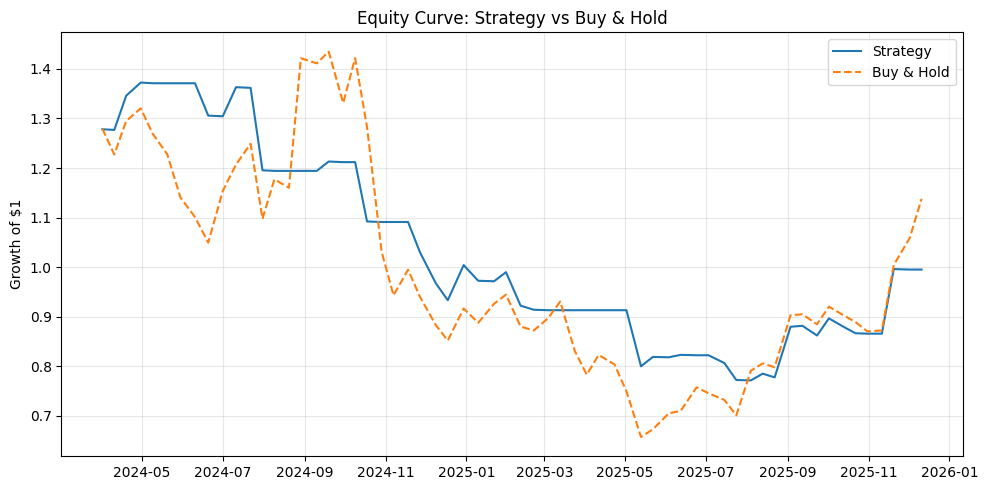

In [34]:
# from backtest import get_test_predictions, run_backtest, print_metrics, plot_equity_curve

results = get_test_predictions(model, data_module)

metrics, equity_df = run_backtest(
    results,
    forecast_horizon=7,          # must match create_sequences_returns()
    short_on_sell=False,         # True to also trade the short side
    cost_per_trade=0.001,        # tune to your real trading costs
    confidence_threshold=0.0,    # e.g. 0.40 to filter low-conviction trades
)

print_metrics(metrics)
plot_equity_curve(equity_df)

In [35]:
from sklearn.metrics import classification_report, confusion_matrix

print("Classification Report:")
print(
    classification_report(
        results["true_class"],
        results["pred_class"],
        labels=[0, 1, 2],
        target_names=["Sell", "Hold", "Buy"],
        digits=3,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        results["true_class"],
        results["pred_class"],
        labels=[0, 1, 2]
    )
)

Classification Report:
              precision    recall  f1-score   support

        Sell      0.432     0.264     0.328       182
        Hold      0.057     0.115     0.076        52
         Buy      0.415     0.452     0.433       199

    accuracy                          0.333       433
   macro avg      0.301     0.277     0.279       433
weighted avg      0.379     0.333     0.346       433

Confusion Matrix:
[[48 46 88]
 [ 7  6 39]
 [56 53 90]]


In [36]:
from sklearn.metrics import f1_score, accuracy_score

y_true = results["true_class"].astype(int).to_numpy()
y_pred = results["pred_class"].astype(int).to_numpy()

always_buy = np.full_like(y_true, 2)

print("LSTM accuracy:",
      round(accuracy_score(y_true, y_pred), 3))
print("Always-Buy accuracy:",
      round(accuracy_score(y_true, always_buy), 3))

print("LSTM macro F1:",
      round(f1_score(y_true, y_pred, average="macro"), 3))
print("Always-Buy macro F1:",
      round(f1_score(y_true, always_buy, average="macro"), 3))

LSTM accuracy: 0.333
Always-Buy accuracy: 0.46
LSTM macro F1: 0.279
Always-Buy macro F1: 0.21


In [37]:
print("Class distribution:")
print(pd.Series(y).value_counts().sort_index())

Class distribution:
0.0    1160
1.0     461
2.0    1262
Name: count, dtype: int64


In [38]:
print("Prediction distribution:")
print(results["pred_class"].value_counts().sort_index())

print("True class distribution:")
print(results["true_class"].value_counts().sort_index())

Prediction distribution:
pred_class
0    111
1    105
2    217
Name: count, dtype: int64
True class distribution:
true_class
0    182
1     52
2    199
Name: count, dtype: int64


In [39]:
# ==========================================
# 1. Classification metrics from current run
# ==========================================

y_true = results["true_class"].astype(int).to_numpy()
y_pred = results["pred_class"].astype(int).to_numpy()

labels = [0, 1, 2]
class_names = ["Sell", "Hold", "Buy"]

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true, y_pred, labels=labels,
    average="macro", zero_division=0
)

# Baseline: always predict Buy
always_buy = np.full(len(y_true), 2)
baseline_accuracy = accuracy_score(y_true, always_buy)
baseline_f1 = f1_score(
    y_true, always_buy, labels=labels,
    average="macro", zero_division=0
)

report = classification_report(
    y_true, y_pred,
    labels=labels,
    target_names=class_names,
    zero_division=0,
    digits=3
)

cm = confusion_matrix(y_true, y_pred, labels=labels)

# ==========================================
# 2. Backtest using current predictions
# ==========================================

backtest_metrics, backtest_df = run_backtest(
    results,
    forecast_horizon=7,
    short_on_sell=False,
    cost_per_trade=0.001,
    confidence_threshold=0.0
)

# ==========================================
# 3. Print classification report
# ==========================================

print("=" * 65)
print("GOLD PRICE PREDICTION — MODEL EVALUATION REPORT")
print("=" * 65)

print("\n1. CLASSIFICATION PERFORMANCE")
print("-" * 65)
print(f"Number of test samples : {len(y_true)}")
print(f"LSTM Accuracy          : {accuracy:.3f}")
print(f"Always-Buy Accuracy    : {baseline_accuracy:.3f}")
print(f"LSTM Macro F1          : {macro_f1:.3f}")
print(f"Always-Buy Macro F1    : {baseline_f1:.3f}")

print("\nClassification Report:")
print(report)

print("Confusion Matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(
    cm,
    index=[f"Actual {name}" for name in class_names],
    columns=[f"Predicted {name}" for name in class_names]
))

# ==========================================
# 4. Print financial results from this run
# ==========================================

print("\n2. BACKTEST PERFORMANCE")
print("-" * 65)

# Show the exact metrics returned by the existing backtest function.
if isinstance(backtest_metrics, dict):
    for name, value in backtest_metrics.items():
        if isinstance(value, (int, float, np.integer, np.floating)):
            print(f"{name:<30}: {value}")
        else:
            print(f"{name:<30}: {value}")
else:
    print(backtest_metrics)

# ==========================================
# 5. Automatic interpretation
# ==========================================

print("\n3. AUTOMATIC INTERPRETATION")
print("-" * 65)

if macro_f1 > baseline_f1:
    print(
        "Classification: LSTM has a higher Macro F1 than "
        "the Always-Buy baseline."
    )
elif macro_f1 < baseline_f1:
    print(
        "Classification: LSTM has a lower Macro F1 than "
        "the Always-Buy baseline."
    )
else:
    print(
        "Classification: LSTM and Always-Buy have the same Macro F1."
    )

if accuracy > baseline_accuracy:
    print("Accuracy: LSTM is more accurate than the Always-Buy baseline.")
else:
    print(
        "Accuracy: LSTM does not outperform the Always-Buy baseline "
        "in accuracy."
    )

class_f1 = f1_score(
    y_true, y_pred, labels=labels,
    average=None, zero_division=0
)

weakest_class = class_names[int(np.argmin(class_f1))]
print(
    f"Class with the lowest F1-score: {weakest_class} "
    f"({np.min(class_f1):.3f})."
)

print(
    "\nFinancial interpretation: compare the strategy's return, "
    "risk and maximum drawdown with Buy & Hold. Better classification "
    "metrics do not necessarily imply a more profitable strategy."
)

print(
    "\nLimitations: results depend on the selected asset, test period, "
    "class thresholds, transaction-cost assumptions and backtest design. "
    "Past backtest performance does not guarantee future returns."
)

print("\n" + "=" * 65)
print("END OF REPORT")
print("=" * 65)

GOLD PRICE PREDICTION — MODEL EVALUATION REPORT

1. CLASSIFICATION PERFORMANCE
-----------------------------------------------------------------
Number of test samples : 433
LSTM Accuracy          : 0.333
Always-Buy Accuracy    : 0.460
LSTM Macro F1          : 0.279
Always-Buy Macro F1    : 0.210

Classification Report:
              precision    recall  f1-score   support

        Sell      0.432     0.264     0.328       182
        Hold      0.057     0.115     0.076        52
         Buy      0.415     0.452     0.433       199

    accuracy                          0.333       433
   macro avg      0.301     0.277     0.279       433
weighted avg      0.379     0.333     0.346       433

Confusion Matrix (rows = actual, columns = predicted):
             Predicted Sell  Predicted Hold  Predicted Buy
Actual Sell              48              46             88
Actual Hold               7               6             39
Actual Buy               56              53             90

2. BA